# EX10: Implement PageRank 

## Overview
In this notebook, you will implement the **PageRank** algorithm.

You will break the work into small steps:
1. Load a graph
2. Construct the transition model
3. Implement PageRank via power iteration
4. Validate with sanity checks
5. Analyze results (top nodes, distribution, sensitivity)

You should have a more intuitive understanding of PageRank after completing the assignment.

You may use `numpy` and `matplotlib` for computations and plots.

**Do not** use `networkx.pagerank` or any other built-in PageRank implementation.


In [27]:
import numpy as np 
import networkx as nx 
import pylab as plot
import pandas as pd

## 1. Load the graph 


Included in the repository is a file `epl_final.csv`. This is a record of all matches in the English Premier League from 2000 - 2025. 

Load the csv with Pandas and transform the data into a graph. You should 
- Filter the dataframe to only matches that occured in the 2024/2025 season. 
- Add a vertex for every unique team
- Add a directed edge A -> B if team B won against team A. 

In [28]:
df = pd.read_csv("epl_final.csv")
# df = dataframe
# Filter for the 2024/2025 season
df = df[df["Season"] == "2024/25"]

# Create a directed graph
G = nx.DiGraph()

# Add every unique team as a vertex
teams = set(df["HomeTeam"]).union(set(df["AwayTeam"]))
G.add_nodes_from(teams)

# Add directed edges from losing team to winning team
for _, row in df.iterrows():

    if row["FullTimeResult"] == "H":
        G.add_edge(row["AwayTeam"], row["HomeTeam"])

    elif row["FullTimeResult"] == "A":
        G.add_edge(row["HomeTeam"], row["AwayTeam"])

print("Number of nodes:", G.number_of_nodes())
print("Number of edges:", G.number_of_edges())

Number of nodes: 20
Number of edges: 198


## 2. Build the transition matrix

Write a function which takes a networkX graph, and constructs the transition matrix from the graph. Recall that the transition matrix is defined as 
$$
\{P_{ij}\} = 
\begin{cases}
\frac{1}{outdeg(v_i)} & (i,j) \in E \\ 
\frac{1}{n} & outdeg(v_i) = 0 \\
0 & \text{otherwise}

\end{cases}
$$

In [29]:
# Your code here 
def buildTransitionMatrix(G):

    nodes = list(G.nodes())
    n = len(nodes)

    P = np.zeros((n, n))

    # Map vertices to matrix indices
    node_index = {v: i for i, v in enumerate(nodes)}

    for i, v in enumerate(nodes):

        neighbors = list(G.successors(v))

        if len(neighbors) > 0:

            for neighbor in neighbors:
                j = node_index[neighbor]
                P[i, j] = 1 / len(neighbors)

        else:
            P[i, :] = 1 / n

    return P

# 2.5 Build the full transition matrix (with teleportation)

Recall the matrix actually used in PageRank is the following 
$$
P' = dP + (1-d) \frac{1}{n}J
$$
Where $J$ is the $n \times n$ matrix of all ones. And $d$ is a *damping factor*, a hyperparameter which controls the probablility a teleportation occurs.

In [30]:
# Your code here
def buildFullMatrix(G,d=0.85):

    n = G.number_of_nodes()

    P = buildTransitionMatrix(G)

    J = np.ones((n, n))

    P_full = d * P + (1 - d) * J / n

    return P_full

# 3. PageRank Dense Matrix
Write a function which computes the PageRank of the graph explicitly, through iteration. 

Recall that if the PageRank approximation at step $t$ is $r_t$, 
$$
r_{t+1} = (P')^T r_t
$$

Update $r$ each iteration until either 
- $||r_{t+1} - r_t ||_1 \leq tol$ 
- $t > max\_iter$

In [31]:
def PageRank(G, d=0.85, tol=1e-6, max_iter=200):

    n = G.number_of_nodes()

    # Initial rank vector
    r = np.ones(n) / n

    P = buildFullMatrix(G, d)

    for _ in range(max_iter):

        r_next = P.T @ r

        # Check convergence
        if np.linalg.norm(r_next - r, ord=1) <= tol:
            return r_next

        r = r_next

    return r

r = PageRank(G)

print(f"Sum of entries is {np.sum(r)}, should be close to 1.")
#  IT SHOULD BE CLOSE TO 1.0, but due to numerical errors, it may not be exactly 1.0
#  SHOULD NOT BE CLOSE TO 0.0

Sum of entries is 1.0000000000000004, should be close to 1.


## 3.5 Check against networkx implementation


In [32]:
r_networkx = nx.pagerank(G)

# Convert dictionary to an array in the same node order
r_networkx = np.array([r_networkx[v] for v in G.nodes()])

np.all(np.isclose(r_networkx,r))

np.True_

## 4. PageRank Sparse Iteration
Of course, the real cleverness in PageRank is the insight that you don't need to explictly construct the full matrix, by exploiting this is a graph problem. Use the starter code below to complete a function which performs a single step of PageRank without the dense matrix.

In [33]:
def pagerank_step(G, r, d=0.85):

    nodes = list(G.nodes())
    n = G.number_of_nodes()

    r_next = np.zeros(n, dtype=float)

    node_index = {v: i for i, v in enumerate(nodes)}

    # Teleportation contribution
    r_next += (1 - d) / n


    # Calculate dangling node contribution
    dangling_mass = 0

    # Propagate rank through the graph
    # Iterate over all vertices
    # Propagate each vertex influence to its out-neighbors.
    # Vertices with outdegree 0 should be handled differently.
    for i, v in enumerate(nodes):

        neighbors = list(G.successors(v))

        if len(neighbors) == 0:

            dangling_mass += r[i]

        else:

            contribution = d * r[i] / len(neighbors)

            for neighbor in neighbors:

                j = node_index[neighbor]
                r_next[j] += contribution

    # Distribute dangling node contribution uniformly
    r_next += d * dangling_mass / n

    return r_next

## 4.5 PageRank Sparse Power Iteration
Again, write a function which iteratively updates a vector until convergence

In [34]:
def PageRank_Sparse(G,d=0.85, tol=1e-6, max_iter=200):
    n = G.number_of_nodes()

    # Initial uniform rank distribution
    r = np.ones(n) / n

    for _ in range(max_iter):

        r_next = pagerank_step(G, r, d)

        # Check convergence
        if np.linalg.norm(r_next - r, ord=1) <= tol:
            return r_next

        r = r_next

    return r

Again, do a small sanity check against your previous and networkx implmentation.

In [35]:
# your code here

r_dense = PageRank(G)
r_sparse = PageRank_Sparse(G)

r_networkx_dict = nx.pagerank(G)
r_networkx = np.array([r_networkx_dict[v] for v in G.nodes()])

print("Dense vs Sparse:",
      np.allclose(r_dense, r_sparse))

print("Sparse vs NetworkX:",
      np.allclose(r_sparse, r_networkx))

print("Sum of PageRank scores:", np.sum(r_sparse))

Dense vs Sparse: True
Sparse vs NetworkX: True
Sum of PageRank scores: 0.9999999999999999


## Sparse vs. Full 
You should conduct the below results on the `Wiki-Vote.txt` data (edgelist). This data includes a directed edge A -> B if user A voted to promote user B to an admin role on Wikipedia.

You can verify that such a large graph will be very slow (or even run out of memory) on the full dense matrix implementation.

## 5. Results: top nodes by PageRank

### Task
- Print the top-10 nodes by PageRank score
- Include their scores

Write a short 2-3 sentences on how these scores can be interpreted in your data.


In [36]:
G = nx.read_edgelist(
    "Wiki-Vote.txt",
    create_using=nx.DiGraph(),
    nodetype=int,
    comments="#"
)

print("Number of nodes:", G.number_of_nodes())
print("Number of edges:", G.number_of_edges())

r = PageRank_Sparse(G)

Number of nodes: 7115
Number of edges: 103689


In [37]:
nodes = list(G.nodes())

# Get indices of the 10 highest PageRank scores
top_indices = np.argsort(r)[::-1][:10]

print("Top 10 nodes by PageRank:\n")

for i in top_indices:

    print(f"Node: {nodes[i]}, PageRank: {r[i]:.8f}")

Top 10 nodes by PageRank:

Node: 4037, PageRank: 0.00460717
Node: 15, PageRank: 0.00367986
Node: 6634, PageRank: 0.00358678
Node: 2625, PageRank: 0.00328366
Node: 2398, PageRank: 0.00260864
Node: 2470, PageRank: 0.00252377
Node: 2237, PageRank: 0.00249663
Node: 4191, PageRank: 0.00226785
Node: 7553, PageRank: 0.00216973
Node: 5254, PageRank: 0.00215010


# my answer

The nodes with the highest PageRank scores are users who receive votes from other influential users. 
A high PageRank score therefore indicates that a user is important within the voting network, not necessarily that they have the highest number of outgoing votes. These users have a relatively strong position in the network because of both the number and importance of the users voting for them.

## 6. Light analysis

### 6.1 Distribution of PageRank scores
Plot a histogram of PageRank scores.

Questions to answer:
- Is the distribution highly skewed?
- Do most nodes have very small score?


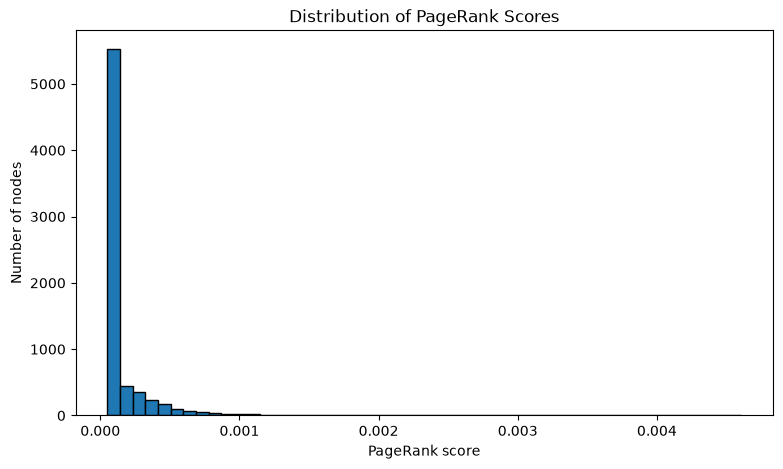

In [38]:
import matplotlib.pyplot as plt
plt.figure(figsize=(9, 5))

plt.hist(r, bins=50, edgecolor="black")

plt.xlabel("PageRank score")
plt.ylabel("Number of nodes")
plt.title("Distribution of PageRank Scores")

plt.show()

# my answers

Is the distribution highly skewed?

Yes. The distribution is strongly right-skewed, meaning that a small number of nodes have considerably higher PageRank scores than the majority.



Do most nodes have very small scores?

Yes. Most nodes have relatively small PageRank scores, while only a small number of nodes have comparatively high scores.


### 6.2 Compare damping factors

Run PageRank with different damping factors and compare:
- `d = 0.70`, `0.85`, `0.95`

Tasks:
1. Compute rank vectors for each `d`
2. Compare the **top-10 overlap** between settings
3. Compute L1 distances between the resulting rank vectors

Answer briefly:
- Which nodes are stable across damping factors?
- Does higher `d` concentrate more probability on a smaller set of nodes?


In [39]:
d_values = [0.70, 0.85, 0.95]

# Calculate PageRank for each damping factor
ranks = {}

for d in d_values:

    ranks[d] = PageRank_Sparse(G, d=d, tol=1e-10, max_iter=1000)


# Get top 10 nodes for each damping factor
top_nodes = {}

for d in d_values:

    indices = np.argsort(ranks[d])[::-1][:10]

    top_nodes[d] = [nodes[i] for i in indices]

    print(f"\nTop 10 nodes for d = {d}:")
    print(top_nodes[d])


# Compare top-10 overlap
print("\nTop-10 overlap:")

for i in range(len(d_values)):

    for j in range(i + 1, len(d_values)):

        d1 = d_values[i]
        d2 = d_values[j]

        overlap = set(top_nodes[d1]) & set(top_nodes[d2])

        print(f"{d1} vs {d2}: {len(overlap)} common nodes")
        print("Common nodes:", sorted(overlap))


# Calculate L1 distances
print("\nL1 distances:")

for i in range(len(d_values)):

    for j in range(i + 1, len(d_values)):

        d1 = d_values[i]
        d2 = d_values[j]

        distance = np.linalg.norm(
            ranks[d1] - ranks[d2],
            ord=1
        )

        print(f"{d1} vs {d2}: {distance:.6f}")


Top 10 nodes for d = 0.7:
[4037, 15, 2625, 6634, 2470, 2237, 2398, 1186, 4191, 5254]

Top 10 nodes for d = 0.85:
[4037, 15, 6634, 2625, 2398, 2470, 2237, 4191, 7553, 5254]

Top 10 nodes for d = 0.95:
[4037, 6634, 15, 2625, 2398, 2237, 4191, 2470, 7553, 5254]

Top-10 overlap:
0.7 vs 0.85: 9 common nodes
Common nodes: [15, 2237, 2398, 2470, 2625, 4037, 4191, 5254, 6634]
0.7 vs 0.95: 9 common nodes
Common nodes: [15, 2237, 2398, 2470, 2625, 4037, 4191, 5254, 6634]
0.85 vs 0.95: 10 common nodes
Common nodes: [15, 2237, 2398, 2470, 2625, 4037, 4191, 5254, 6634, 7553]

L1 distances:
0.7 vs 0.85: 0.151647
0.7 vs 0.95: 0.252670
0.85 vs 0.95: 0.101638


# my answers
Which nodes are stable across damping factors?

Most of the top-ranked nodes remain stable across all three damping factors. In particular, nodes 4037, 15, 6634, 2625, 2398, 2470, 2237, 4191 and 5254 appear in the top 10 for all three settings.



Does higher \(d\) concentrate more probability on a smaller set of nodes?

Yes. A higher damping factor reduces the probability of teleportation and places more emphasis on following existing edges. Consequently, the PageRank distribution becomes more dependent on the network structure, allowing influential nodes to accumulate a larger share of the probability.


### 6.3 Relationship with out-degree

Compute correlation between PageRank and out-degree.

Questions:
- Are high PageRank nodes necessarily high out-degree nodes?
- What do you observe in the scatter plot?


Correlation between PageRank and out-degree: 0.253805839297947


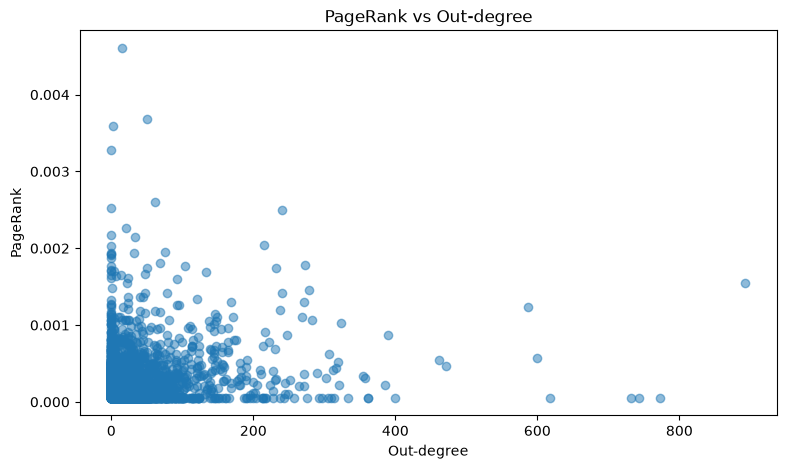

In [40]:
# Calculate out-degree for every node
out_degrees = np.array([
    G.out_degree(v) for v in nodes
])

# Calculate correlation
correlation = np.corrcoef(r, out_degrees)[0, 1]

print("Correlation between PageRank and out-degree:",
      correlation)


# Create scatter plot
plt.figure(figsize=(9, 5))

plt.scatter(out_degrees, r, alpha=0.5)

plt.xlabel("Out-degree")
plt.ylabel("PageRank")
plt.title("PageRank vs Out-degree")

plt.show()

# my answers

- Are high PageRank nodes necessarily high out-degree nodes?
  
  No. A node can have a high PageRank score even with a relatively low out-degree. PageRank primarily depends on incoming links and the importance of the nodes providing those links, whereas out-degree measures the number of outgoing links.
- What do you observe in the scatter plot?
  
  The scatter plot shows a relatively weak positive relationship between out-degree and PageRank. This indicates that having many outgoing links does not necessarily result in a high PageRank score.